# 06 — The centroid baseline

A common way to build yield-model features: every dataset except NDVI is the single pixel under the field centroid, on the source raster; NDVI is the field's all-touched zonal mean per August scene, then the mean over scenes.
This notebook builds that baseline and compares it with the H3 scores.

In [0]:
%run ./config_nb

geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: JVM level unavailable: Spark Connect session (Serverless); using the Python level (48 functions)
geobrix: SQL expression level unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using the Python level


... EARTHDATA_TOKEN loaded from geospatial_docs.vapor_eyes.earthdata_token


True

DataFrame[]

H3PX_DIR = /Volumes/geospatial_docs/h3_pixels_crop_yield/data/h3-pixels-crop-yield


... view helpers: show_cells, show_tile (gated by INTERACTIVE_PLOTS)


## Sample the source rasters at each field centroid

The same pixel is read every day, so the monthly reduction is the one the dataset layer uses (`monthly_reduce`).
Where a dataset has one tile per day, the tiles of a month are stacked into one tile with a band per day, so a centroid is sampled once per month.
`gbx_rst_sample` returns the pixel that holds the point, as rasterio `sample` does.

In [0]:
fields = spark.table("field_polys").select("field_id", "season", "centroid_in_poly",
                                           F.expr("st_asbinary(field_centroid)").alias("pt"))


def sampled(key, dataset, attr, how, months, scale):
    """The source pixel under each field centroid, per band date, reduced to months by monthly_reduce."""
    t = dataset_tiles(key)
    rule = t.select("band_date_rule").first()["band_date_rule"]
    day, extra = band_to_date_sql(rule), []
    if rule == "tile_date":
        # One tile per day: stack the daily tiles of each scored month into one tile with a band per day (`dates`
        # holds the day of each band), so a centroid is sampled once per field and month, not once per field and day.
        by_date = "(a, b) -> CASE WHEN a.collect_date < b.collect_date THEN -1 WHEN a.collect_date > b.collect_date THEN 1 ELSE 0 END"
        t = (t.where(F.month("collect_date").isin(list(months)))
             .groupBy(F.trunc("collect_date", "month").alias("month"))
             .agg(F.expr(f"array_sort(collect_list(struct(collect_date, tile)), {by_date})").alias("s"))
             .selectExpr("month AS collect_date", "transform(s, x -> x.collect_date) AS dates",
                         "gbx_rst_frombands(transform(s, x -> x.tile)) AS tile"))
        day, extra = "element_at(dates, band)", ["dates"]
    # posexplode_outer + a filter on pos samples each pair once (a plain posexplode can sample it twice).
    j = (t.join(fields, F.year(t.collect_date) == fields.season)
         .repartition(FANOUT, "field_id")
         .selectExpr("field_id", "season", "centroid_in_poly", "collect_date", *extra,
                     "posexplode_outer(gbx_rst_sample(tile, pt, 'EPSG:4326')) AS (pos, v)")
         .where("pos IS NOT NULL")
         .withColumn("band", F.col("pos") + 1)
         .withColumn("day", F.expr(day)))
    m = monthly_reduce(j, "v", how, months, scale, ["field_id", "season", "centroid_in_poly"])
    return m.select("field_id", "season", F.lit(dataset).alias("dataset"), "collect_date", F.lit(attr).alias("attr_name"),
                    F.col("measure").alias("sample_measure"), "centroid_in_poly")


by_attr = {(dataset, attr): sampled(key, dataset, attr, how, months, scale)
           for key, dataset, attr, how, months, scale in ATTRIBUTES}
st4, nrm = by_attr[("stage4", "precip_mm")].alias("s"), by_attr[("normals", "precip_normal_mm")].alias("n")
parts = list(by_attr.values())
parts.append(st4.join(nrm, ["field_id", "season", "collect_date", "centroid_in_poly"])
             .select("field_id", "season", F.lit("precip_anomaly").alias("dataset"), "collect_date",
                     F.lit("precip_anom_mm").alias("attr_name"),
                     (F.col("s.sample_measure") - F.col("n.sample_measure")).alias("sample_measure"), "centroid_in_poly"))

## NDVI the baseline way

Per August scene, NDVI with the cloud bit masked is built once over the area of interest and cut into sub-tiles.
Each field poly is clipped out of the sub-tiles it meets, keeping every pixel it touches, and the scene's mean is the sum over the count of the valid pixels of those pieces.
The field's value is the mean over the scenes with a valid mean.

In [0]:
if EARTHDATA_READY:
    # The NDVI tile of each scene over the AOI is built once and cut into sub-tiles. Each field is clipped out of the
    # sub-tiles its poly meets, and a scene's mean is the sum over the count of the valid pixels of those pieces.
    # The sub-tile box goes through an OUTER generator, so it is computed once per sub-tile.
    aoi = aoi_wkt()
    src = [f"gbx_rst_fromfile({c}, 'GTiff', '{aoi}', 'EPSG:4326')" for c in ("red_path", "nir_path", "fmask_path")]
    (hls.read_scenes(spark, HLS_DIR).where(F.year("collect_date").isin(SEASONS)).repartition(FANOUT, "scene_id")
     .selectExpr("scene_id", "collect_date", f"{ndvi_sql(*src)} AS tile").createOrReplaceTempView("_hls_ndvi"))
    spark.sql(f"""SELECT s.scene_id, s.collect_date, struct(t.*) AS tile
                  FROM _hls_ndvi s, LATERAL gbx_rst_retile(s.tile, {RETILE_PX}, {RETILE_PX}) t""") \
        .repartition(FANOUT, "scene_id", "tile.window") \
        .selectExpr("scene_id", "collect_date", "tile",
                    "array(st_setsrid(st_geomfromwkb(gbx_rst_boundingbox(tile)), gbx_rst_srid(tile))) AS boxes") \
        .selectExpr("scene_id", "collect_date", "tile", "explode_outer(boxes) AS bbox") \
        .selectExpr("scene_id", "collect_date", "tile", "st_srid(bbox) AS srid", "bbox") \
        .createOrReplaceTempView("_hls_boxes")
    spark.table("field_polys").createOrReplaceTempView("_fp")
    pieces = spark.sql("""
      SELECT /*+ BROADCAST(f) */ f.field_id, f.season, f.centroid_in_poly, b.scene_id,
             gbx_rst_stats_partial(gbx_rst_clip(b.tile, st_asbinary(f.field_poly), true, 'EPSG:4326'))[0] AS st
      FROM _hls_boxes b JOIN _fp f
        ON year(b.collect_date) = f.season AND st_intersects(st_transform(f.field_poly, b.srid), b.bbox)""")
    zonal = pieces.groupBy("field_id", "season", "centroid_in_poly", "scene_id") \
        .agg(F.expr("try_divide(sum(st.sum), sum(st.count))").alias("scene_mean"))
    parts.append(zonal.groupBy("field_id", "season", "centroid_in_poly")
                 .agg(F.avg("scene_mean").alias("sample_measure"))
                 .select("field_id", "season", F.lit("hls").alias("dataset"), F.expr("make_date(season, 8, 1)").alias("collect_date"),
                         F.lit("ndvi_aug_mean").alias("attr_name"), "sample_measure", "centroid_in_poly"))
centroid = _persist(functools.reduce(DataFrame.unionByName, parts), "h3_field_measures_centroid", cluster_by=["field_id"])

... wrote table h3_field_measures_centroid (105,000 rows)


## Compare the baseline with the H3 scores

Per attribute, the gap between the centroid value and the two field scores, counted in field-months (one row per field and month; NDVI has one, August).
Interior fields (centroid inside the poly and at least `EDGE_WEIGHT_D_M` from the edge) are kept apart from the others, and the largest gaps are listed.

In [0]:
spark.sql(f"""
  WITH e AS (SELECT field_id, season, st_distance(st_transform(field_centroid, 5070),
                                                   st_boundary(st_transform(field_poly, 5070))) AS ctr_edge_m FROM field_polys)
  SELECT field_id, season, dataset, collect_date, attr_name, c.sample_measure, b.score_unweighted, b.score_edge_weighted,
         CASE WHEN c.centroid_in_poly AND e.ctr_edge_m >= {EDGE_WEIGHT_D_M} THEN 'interior' ELSE 'edge or outside' END AS kind
  FROM h3_field_measures_centroid c
  JOIN h3_field_measures_blended b USING (field_id, season, dataset, collect_date, attr_name)
  JOIN e USING (field_id, season)""").createOrReplaceTempView("_gaps")
cmp = spark.sql("""
  SELECT attr_name, kind, count(*) AS field_months,
         percentile_approx(sample_measure - score_unweighted, array(0.05, 0.5, 0.95), 10000) AS gap_unweighted_p5_p50_p95,
         percentile_approx(sample_measure - score_edge_weighted, array(0.05, 0.5, 0.95), 10000) AS gap_edge_weighted_p5_p50_p95
  FROM _gaps GROUP BY 1, 2 ORDER BY 1, 2""")
display(cmp)
display(spark.sql("""SELECT field_id, dataset, attr_name, collect_date, sample_measure, score_edge_weighted,
                            abs(sample_measure - score_edge_weighted) AS gap
                     FROM _gaps ORDER BY gap DESC LIMIT 20"""))

attr_name,kind,field_months,gap_unweighted_p5_p50_p95,gap_edge_weighted_p5_p50_p95
gws_inst,edge or outside,2380,"[-3.7748099527091767, 0.0, 3.594350865453027]","[-3.7748099527091803, 0.0, 3.5943508654530305]"
gws_inst,interior,11608,"[-3.7534468613467986, 0.0, 3.904247125988098]","[-3.7534468613468004, 0.0, 3.904247125988098]"
ndvi_aug_mean,edge or outside,595,"[-0.05365613138273706, -0.0059946315522376725, 0.014420093710080795]","[-0.057525780442461594, -0.00662579179766698, 0.014600794509871617]"
ndvi_aug_mean,interior,2902,"[-0.03324711078718434, -0.009851849769014542, 0.002779476369830669]","[-0.03708603380417519, -0.011485413103673014, 0.002805402356967135]"
precip_anom_mm,edge or outside,2975,"[-8.53631661269965, -2.1316282072803006e-14, 8.698802205409564]","[-8.585606811343666, -2.1316282072803006e-14, 8.76815761026294]"
precip_anom_mm,interior,14510,"[-8.296514902654037, -2.2737367544323206e-13, 8.747148423337777]","[-8.31642062945518, -1.9184653865522705e-13, 8.768741165827997]"
precip_mm,edge or outside,2975,"[-8.383985160294856, 0.0, 8.940614958177932]","[-8.493137103820104, 0.0, 8.890554103527357]"
precip_mm,interior,14510,"[-8.211370835252552, 0.0, 8.807389157233217]","[-8.232422511745952, -1.4210854715202004e-14, 8.813990911971288]"
precip_normal_mm,edge or outside,2975,"[-0.8344587043874299, 0.0, 0.8451480091677013]","[-0.8357927144706565, 2.842170943040401e-14, 0.8418271287593484]"
precip_normal_mm,interior,14510,"[-0.8803254850444091, 0.0, 0.8974208455583721]","[-0.8823685564687338, 0.0, 0.8991346956066764]"


field_id,dataset,attr_name,collect_date,sample_measure,score_edge_weighted,gap
191825002945414,precip_anomaly,precip_anom_mm,2023-09-01,-5.553325891494751,-52.043513177591834,46.49018728609708
191825002945414,stage4,precip_mm,2023-09-01,106.89999747276306,60.40981018666599,46.49018728609707
191825003868026,stage4,precip_mm,2023-08-01,96.49999647065997,135.60108474172733,39.10108827106737
191825003868026,precip_anomaly,precip_anom_mm,2023-08-01,-21.63132066801191,16.613501646708716,38.24482231472062
191825002944091,precip_anomaly,precip_anom_mm,2023-09-01,-59.65006819441915,-22.5979320681197,37.052136126299445
191825002944091,stage4,precip_mm,2023-09-01,51.60000047013163,87.9198671309019,36.31986666077027
191825003868024,stage4,precip_mm,2023-08-01,163.40000045578927,127.15250567562937,36.2474947801599
191825003868007,stage4,precip_mm,2023-08-01,163.40000045578927,127.15250567562954,36.24749478015973
191825003868007,precip_anomaly,precip_anom_mm,2023-08-01,42.70599258225411,6.743626019665696,35.962366562588414
191825003868024,precip_anomaly,precip_anom_mm,2023-08-01,42.70599258225411,6.743626019665706,35.96236656258841


## Where one dataset cell covers the field

When every kept cell of a field links to one dataset cell at 100%, the centroid pixel and the field score read the same place, so they should agree closely.
The dataset cell is smaller than a source pixel, but it can straddle a pixel edge: its value is then the area-weighted mean of the pixels it overlaps, while the centroid reads one of them.
The smooth datasets, the normals and the wind, agree within 1% (`ALIGNED_TOL`; medians 0.13% and 0.13%), which shows the two grids line up.
Stage IV precipitation (median 1.8%) and the GRACE-DA groundwater and soil-moisture percentiles (5.0% and 2.2%) change more from one pixel to the next, so a straddling cell moves further from its centroid pixel; they only have to stay within `OTHER_TOL` (10%).
For example, in September 2023 one res-7 cell lies about two thirds on a Stage IV pixel of 98 mm and one third on a pixel of 49 mm, so its value is 82 mm, while a field whose centroid falls in the second pixel reads 49 mm.

In [0]:
ALIGNED_TOL = 0.01   # the smooth datasets read the same cell as the pixel: a median gap of at most 1% shows the grids line up
OTHER_TOL = 0.10     # the others differ between neighbouring pixels: a sanity bound, not an agreement test
ALIGNED = {("normals", "precip_normal_mm"), ("gridmet", "wind_speed_ms")}

k = spark.sql("""SELECT count(*) AS n, count(sample_measure) AS valid FROM h3_field_measures_centroid""").first()
assert k["n"] > 0 and k["valid"] / k["n"] > 0.95
# One-cell field-months: every kept field cell links to the same dataset cell at 100% (per dataset, attribute, month).
# Only the coarse datasets: an HLS field cell's shares sum to the clear share, so HLS has no 100% cell.
coarse = {(dataset, attr) for _, dataset, attr, *_ in ATTRIBUTES}  # every attribute but NDVI is on res 6-7 cells
coarse_datasets = ", ".join(f"'{d}'" for d in sorted({d for d, _ in coarse}))
spark.sql(f"""
  SELECT field_id, year(collect_date) AS season, dataset, collect_date, attr_name
  FROM h3_field_measures_perc WHERE dataset IN ({coarse_datasets})
  GROUP BY field_id, year(collect_date), dataset, collect_date, attr_name
  HAVING count(DISTINCT attr_h3_cellid) = 1 AND min(field_attr_perc) >= 100.0 - 1e-6""").createOrReplaceTempView("_one_cell")
agree = spark.sql("""
  SELECT dataset, attr_name, count(*) AS field_months,
         percentile_approx(abs(sample_measure - score_unweighted) / abs(score_unweighted), 0.5, 10000) AS median_rel_gap
  FROM _gaps JOIN _one_cell USING (field_id, season, dataset, collect_date, attr_name)
  WHERE score_unweighted <> 0 AND sample_measure IS NOT NULL
  GROUP BY 1, 2 ORDER BY 1, 2""").collect()
for r in agree:
    print(f"{r['dataset']}/{r['attr_name']}: {r['field_months']:,} one-cell field-months, "
          f"median |centroid - field| / |field| = {r['median_rel_gap']:.3%}")
checked = {(r["dataset"], r["attr_name"]): r["median_rel_gap"] for r in agree if (r["dataset"], r["attr_name"]) in coarse}
assert ALIGNED <= checked.keys(), "no one-cell field-month for a smooth dataset"
for key, gap in checked.items():
    tol = ALIGNED_TOL if key in ALIGNED else OTHER_TOL
    assert gap <= tol, f"{key}: median gap {gap:.3%} above {tol:.0%} on one-cell field-months"

grace/gws_inst: 11,632 one-cell field-months, median |centroid - field| / |field| = 5.016%
grace/sfsm_inst: 14,540 one-cell field-months, median |centroid - field| / |field| = 2.241%
gridmet/wind_speed_ms: 10,820 one-cell field-months, median |centroid - field| / |field| = 0.134%
normals/precip_normal_mm: 10,820 one-cell field-months, median |centroid - field| / |field| = 0.129%
stage4/precip_mm: 10,820 one-cell field-months, median |centroid - field| / |field| = 1.823%


## Payoff

The baseline feature set and the H3 scores side by side for every field: each panel is the gap, centroid minus edge-weighted score, for one attribute, with interior fields against the others.
The smooth datasets, the normals and wind speed, sit on zero (5th to 95th percentile within 0.9 mm and 0.04 m/s).
Monthly precipitation and its anomaly spread to about -8 and +9 mm, the groundwater percentile to about -3.8 and +3.9 points and the soil-moisture percentile to about -2.4 and +2.6 points, where the centroid pixel and the dataset cell read different pixels.
With HLS staged (`EARTHDATA_READY`), NDVI sits a little lower in the baseline (median -0.011 for interior fields): its mean takes every pixel the poly touches, edge pixels included, where the H3 score keeps cells at least `SETBACK_M` inside the edge.

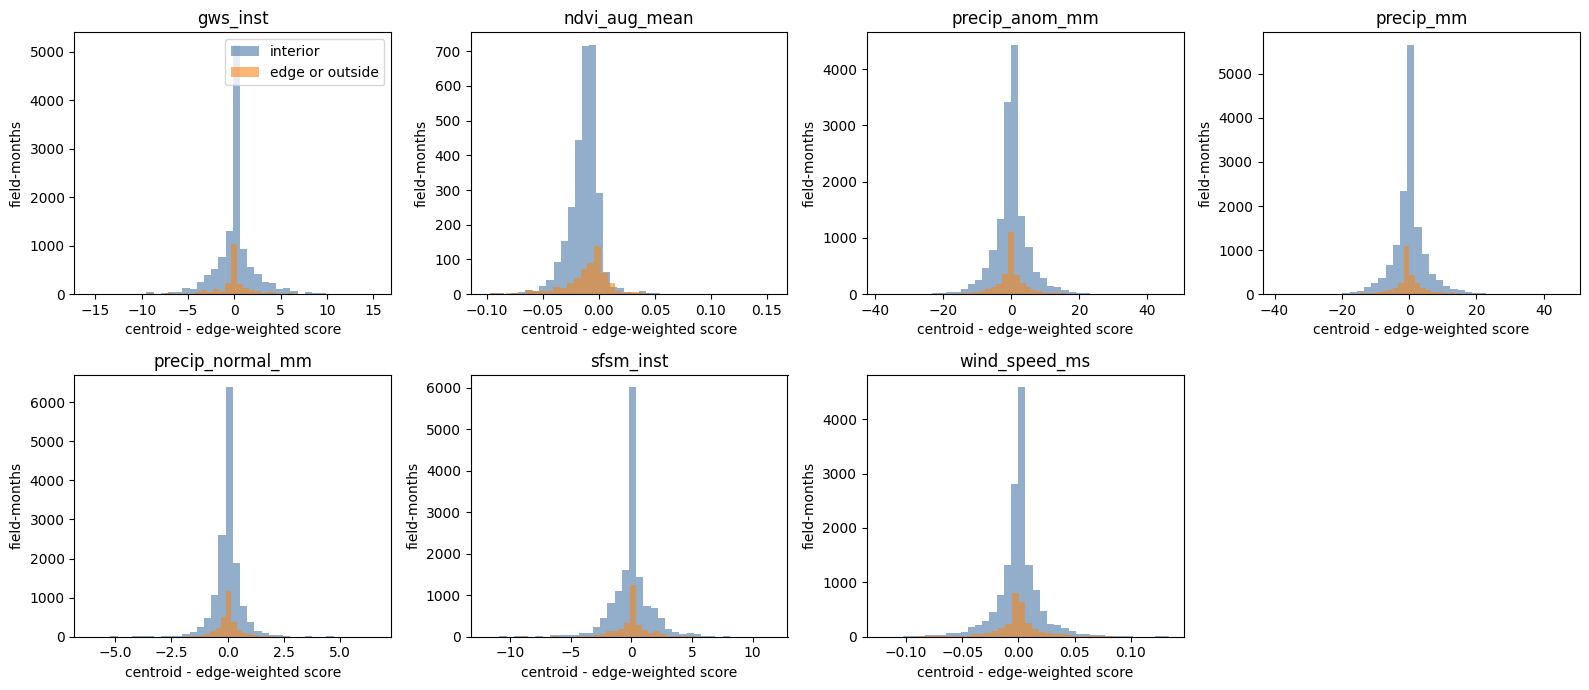

In [0]:
import matplotlib.pyplot as plt

g = spark.sql("""SELECT attr_name, kind, sample_measure - score_edge_weighted AS gap FROM _gaps
                 WHERE sample_measure IS NOT NULL AND score_edge_weighted IS NOT NULL""").toPandas()
attrs = sorted(g["attr_name"].unique())
ncols = 4
nrows = -(-len(attrs) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), squeeze=False)
for ax, a in zip(axes.flat, attrs):
    for kind, colour in (("interior", "#4C78A8"), ("edge or outside", "#F58518")):
        ax.hist(g.loc[(g["attr_name"] == a) & (g["kind"] == kind), "gap"], bins=40, alpha=0.6, color=colour, label=kind)
    ax.set_title(a)
    ax.set_xlabel("centroid - edge-weighted score")
    ax.set_ylabel("field-months")
for ax in axes.flat[len(attrs):]:
    ax.set_visible(False)
axes[0][0].legend()
plt.tight_layout()
plt.show()